# Investigating What Helps Identify Highly Rated Anime

## Research question
**Can we predict whether an anime will receive a high score based on its other features?**

## Aim
This investigation looks at whether information recorded about an anime can help identify titles with a score of 7.5 or higher. It focuses on popularity, release year, episode count, anime format, genre and age rating.

The notebook first looks at the anime data, then tests different groups of features and checks how reliable the predictions are. The score itself is only used to create the high-rated label, not as an input to the model.

## 1. Get the anime data ready
The cleaned dataset was created in the data preparation notebook. This keeps the original dataset unchanged.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)

df = pd.read_csv("../data/cleaned_popular_anime.csv")
df.head()

,id,name,genres,type,episodes,status,aired_from,aired_to,duration_per_ep,score,scored_by,rank,rating,studios,producers,image,trailer,synopsis,release_year
0,52991,Frieren: Beyond Journey's End,"Adventure, Drama, Fantasy",TV,28.0,Finished Airing,2023-09-29 00:00:00+00:00,2024-03-22 00:00:00+00:00,24 min per ep,9.30,676737.0,1.0,PG-13 - Teens 13 or older,Madhouse,"Aniplex, Dentsu, Shogakukan-Shueisha Productio...",https://cdn.myanimelist.net/images/anime/1015/...,https://www.youtube.com/watch?v=ZEkwCGJ3o7M,During their decade-long quest to defeat the D...,2023.0
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy",TV,64.0,Finished Airing,2009-04-05 00:00:00+00:00,2010-07-04 00:00:00+00:00,24 min per ep,9.10,2223666.0,2.0,R - 17+ (violence & profanity),Bones,"Aniplex, Square Enix, Mainichi Broadcasting Sy...",https://cdn.myanimelist.net/images/anime/1208/...,https://www.youtube.com/watch?v=1ac3_YdSSy0,After a horrific alchemy experiment goes wrong...,2009.0
2,9253,Steins;Gate,"Drama, Sci-Fi, Suspense",TV,24.0,Finished Airing,2011-04-06 00:00:00+00:00,2011-09-14 00:00:00+00:00,24 min per ep,9.07,1467570.0,3.0,PG-13 - Teens 13 or older,White Fox,"Frontier Works, Media Factory, Kadokawa Shoten...",https://cdn.myanimelist.net/images/anime/1935/...,https://www.youtube.com/watch?v=27OZc-ku6is,Eccentric scientist Rintarou Okabe has a never...,2011.0
3,38524,Attack on Titan Season 3 Part 2,"Action, Drama, Suspense",TV,10.0,Finished Airing,2019-04-29 00:00:00+00:00,2019-07-01 00:00:00+00:00,23 min per ep,9.05,1700946.0,4.0,R - 17+ (violence & profanity),Wit Studio,"Production I.G, Dentsu, Mainichi Broadcasting ...",https://cdn.myanimelist.net/images/anime/1517/...,https://www.youtube.com/watch?v=hKHepjfj5Tw,Seeking to restore humanity's diminishing hope...,2019.0
4,28977,Gintama Season 4,"Action, Comedy, Sci-Fi",TV,51.0,Finished Airing,2015-04-08 00:00:00+00:00,2016-03-30 00:00:00+00:00,24 min per ep,9.05,264260.0,5.0,PG-13 - Teens 13 or older,Bandai Namco Pictures,"TV Tokyo, Aniplex, Dentsu",https://cdn.myanimelist.net/images/anime/3/720...,NaN,"Gintoki, Shinpachi, and Kagura return as the f...",2015.0


## 2. Define what counts as highly rated
Only anime with a score and at least one recorded rating are used. The number of ratings is log-transformed because it has a wide range.

In [17]:
model_data = df.dropna(subset=["score", "scored_by"]).copy()
model_data = model_data[model_data["scored_by"] > 0].copy()
model_data["high_score"] = (model_data["score"] >= 7.5).astype(int)
model_data["log_scored_by"] = np.log1p(model_data["scored_by"])
model_data["primary_genre"] = (
    model_data["genres"].fillna("Unknown").str.split(",").str[0].str.strip()
)
model_data["primary_genre"] = model_data["primary_genre"].replace("", "Unknown")

print("Rows used:", len(model_data))
print("High-rated anime:", model_data["high_score"].sum())
print("Other anime:", (model_data["high_score"] == 0).sum())
print("High-rated percentage:", round(model_data["high_score"].mean() * 100, 1), "%")

Rows used: 18541
High-rated anime: 2081
Other anime: 16460
High-rated percentage: 11.2 %


## 3. How are anime scores distributed?
The two groups are not the same size, so accuracy alone may not give a fair picture of model performance.

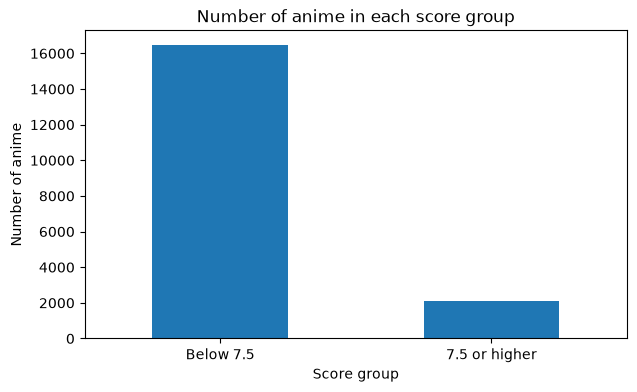

,count,mean,std,min,25%,50%,75%,max
high_score,,,,,,,,
0,16460.0,6.205544,0.743915,1.89,5.70,6.25,6.76,7.49
1,2081.0,7.903758,0.339430,7.50,7.62,7.81,8.11,9.30


In [18]:
score_groups = model_data["high_score"].value_counts().sort_index()
score_groups.index = ["Below 7.5", "7.5 or higher"]
score_groups.plot(kind="bar", figsize=(7, 4), title="Number of anime in each score group")
plt.xlabel("Score group")
plt.ylabel("Number of anime")
plt.xticks(rotation=0)
plt.show()

display(model_data.groupby("high_score")["score"].describe())

## 4. Compare anime characteristics
The charts compare anime with scores below 7.5 against anime scoring 7.5 or above. They help check whether popularity and format look different between the two groups.

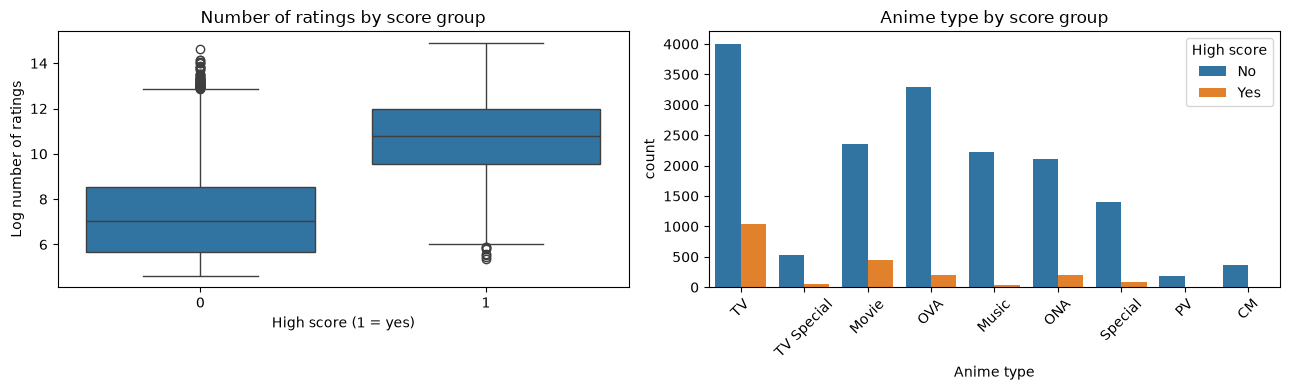

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=model_data, x="high_score", y="log_scored_by", ax=axes[0])
axes[0].set_title("Number of ratings by score group")
axes[0].set_xlabel("High score (1 = yes)")
axes[0].set_ylabel("Log number of ratings")
sns.countplot(data=model_data, x="type", hue="high_score", ax=axes[1])
axes[1].set_title("Anime type by score group")
axes[1].set_xlabel("Anime type")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="High score", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

,anime_count,high_score_rate
primary_genre,,
Award Winning,129,43.410853
Sports,359,27.855153
Drama,1099,20.837125
Action,4610,17.505423
Slice of Life,602,15.946844
Mystery,159,15.094340
Boys Love,153,15.032680
Romance,281,13.167260
Adventure,1435,12.473868


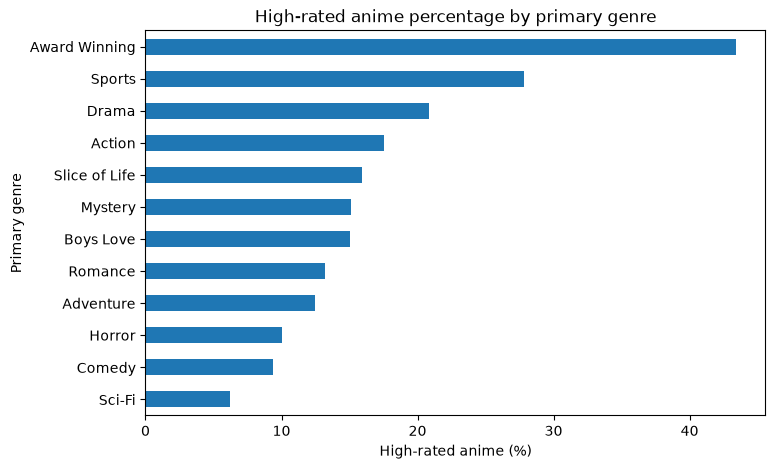

In [20]:
genre_summary = (
    model_data.groupby("primary_genre")
    .agg(anime_count=("id", "count"), high_score_rate=("high_score", "mean"))
    .query("anime_count >= 100")
    .sort_values("high_score_rate", ascending=False)
)
genre_summary["high_score_rate"] *= 100
display(genre_summary.head(12))
genre_summary.head(12)["high_score_rate"].sort_values().plot(
    kind="barh", figsize=(8, 5), title="High-rated anime percentage by primary genre"
)
plt.xlabel("High-rated anime (%)")
plt.ylabel("Primary genre")
plt.show()

## 5. Set up the prediction experiment

To see which details about an anime are useful, the experiment tests three feature groups:
- **Numeric:** number of ratings, episode count and release year.
- **Categorical:** anime type, primary genre and age rating.
- **Combined:** all six features.

The anime's score is not included as a feature because it is used to create the target. Including it would give the model the answer.

In [21]:
numeric_features = ["log_scored_by", "episodes", "release_year"]
categorical_features = ["type", "primary_genre", "rating"]
all_features = numeric_features + categorical_features

X = model_data[all_features]
y = model_data["high_score"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

def make_model(features):
    numeric = [f for f in numeric_features if f in features]
    categorical = [f for f in categorical_features if f in features]
    transformers = []
    if numeric:
        numeric_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        transformers.append(("numeric", numeric_pipe, numeric))
    if categorical:
        categorical_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])
        transformers.append(("categorical", categorical_pipe, categorical))
    preprocessing = ColumnTransformer(transformers)
    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
    ])

## 6. Which information is most useful?
Each model uses the same training and test rows. A majority-class baseline is included for comparison.

In [22]:
feature_sets = {
    "Numeric only": numeric_features,
    "Categorical only": categorical_features,
    "Combined": all_features
}
comparison = []
fitted_models = {}

for name, features in feature_sets.items():
    model = make_model(features)
    model.fit(X_train[features], y_train)
    pred = model.predict(X_test[features])
    prob = model.predict_proba(X_test[features])[:, 1]
    fitted_models[name] = model
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, prob)
    })

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train[all_features], y_train)
base_pred = baseline.predict(X_test[all_features])
comparison.append({
    "Model": "Majority baseline",
    "Accuracy": accuracy_score(y_test, base_pred),
    "Precision": precision_score(y_test, base_pred, zero_division=0),
    "Recall": recall_score(y_test, base_pred, zero_division=0),
    "F1": f1_score(y_test, base_pred, zero_division=0),
    "ROC AUC": np.nan
})
comparison_df = pd.DataFrame(comparison).set_index("Model")
display(comparison_df.round(3))

,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Numeric only,0.807,0.348,0.817,0.488,0.905
Categorical only,0.690,0.234,0.776,0.359,0.793
Combined,0.828,0.379,0.837,0.521,0.913
Majority baseline,0.888,0.000,0.000,0.000,NaN


Accuracy is the percentage of all predictions that are correct. Precision tells us how many anime predicted as high-rated really are high-rated. Recall tells us how many of the actual high-rated anime the model finds. F1 combines precision and recall.

The baseline predicts every anime as not high-rated. It may have high accuracy because most anime are below 7.5, but it does not find any high-rated anime.

## 7. Where does the combined model get predictions right or wrong?

In [23]:
best_model = fitted_models["Combined"]
combined_predictions = best_model.predict(X_test[all_features])
combined_probabilities = best_model.predict_proba(X_test[all_features])[:, 1]

print(classification_report(
    y_test, combined_predictions,
    target_names=["Below 7.5", "7.5 or higher"],
    zero_division=0
))

               precision    recall  f1-score   support

    Below 7.5       0.98      0.83      0.89      3293
7.5 or higher       0.38      0.84      0.52       416

     accuracy                           0.83      3709
    macro avg       0.68      0.83      0.71      3709
 weighted avg       0.91      0.83      0.85      3709



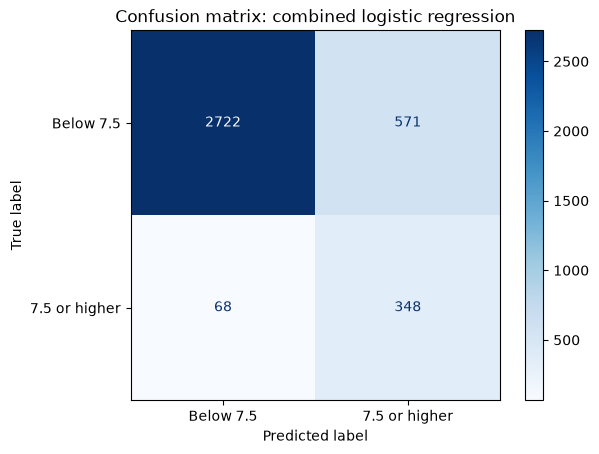

In [24]:
ConfusionMatrixDisplay.from_predictions(
    y_test, combined_predictions,
    display_labels=["Below 7.5", "7.5 or higher"],
    cmap="Blues"
)
plt.title("Confusion matrix: combined logistic regression")
plt.show()

The confusion matrix separates correct predictions from mistakes. False positives are anime predicted as high-rated when their actual score is below 7.5. False negatives are high-rated anime that the model misses.

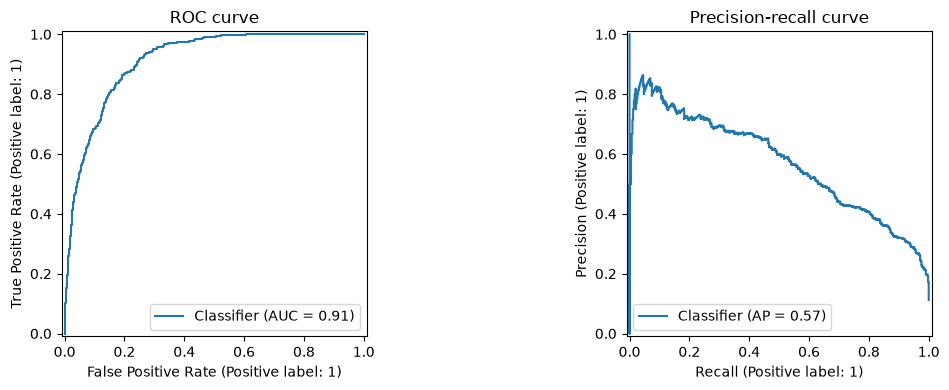

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, combined_probabilities, ax=axes[0])
axes[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, combined_probabilities, ax=axes[1])
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

ROC AUC measures how well the model ranks high-rated anime above other anime across probability cut-offs. The precision-recall curve is also useful because high-rated anime are the smaller group.

## 8. Does the definition of a high score change the outcome?
The choice of 7.5 is one way to define a high score. This experiment checks whether results change if the cut-off is 7.0 or 8.0 instead.

In [26]:
threshold_results = []
for threshold in [7.0, 7.5, 8.0]:
    y_threshold = (model_data["score"] >= threshold).astype(int)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y_threshold, test_size=0.2, random_state=42, stratify=y_threshold
    )
    threshold_model = make_model(all_features)
    threshold_model.fit(X_tr, y_tr)
    pred = threshold_model.predict(X_te)
    prob = threshold_model.predict_proba(X_te)[:, 1]
    threshold_results.append({
        "High score cut-off": threshold,
        "High-rated percentage": y_threshold.mean() * 100,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred, zero_division=0),
        "F1": f1_score(y_te, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_te, prob)
    })
threshold_df = pd.DataFrame(threshold_results).set_index("High score cut-off")
display(threshold_df.round(3))

,High-rated percentage,Accuracy,Precision,Recall,F1,ROC AUC
High score cut-off,,,,,,
7.0,26.013,0.819,0.615,0.815,0.701,0.901
7.5,11.224,0.828,0.379,0.837,0.521,0.913
8.0,3.727,0.854,0.187,0.870,0.307,0.941


A higher cut-off creates a smaller high-rated group. This can make classification harder. The results show whether the model depends heavily on the chosen definition of high-rated.

## 9. Check whether the results are consistent
A single train/test split gives one result. Five-fold stratified cross-validation repeats the evaluation across five splits while keeping the class balance similar in each fold.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_model = make_model(all_features)
cv_results = cross_validate(
    cv_model, X, y, cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)
cv_summary = pd.DataFrame({
    "Mean": {m: cv_results["test_" + m].mean()
             for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
    "Standard deviation": {m: cv_results["test_" + m].std()
                           for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}
})
display(cv_summary.round(3))

,Mean,Standard deviation
accuracy,0.825,0.009
precision,0.377,0.014
recall,0.848,0.014
f1,0.522,0.015
roc_auc,0.915,0.006


The mean is the average result across the five folds. The standard deviation shows how much the result changes between folds. A larger variation means the model is less consistent.

## 10. Which anime features are most strongly associated with high scores?
The fitted model assigns a coefficient to each input after categorical values have been encoded. Positive coefficients are linked with a higher model estimate for the high-score group, while negative coefficients are linked with a lower estimate. These are patterns in this dataset, not causes of anime ratings.

Features most associated with a lower high-score prediction:


,Feature,Coefficient
39,categorical__rating_Rx - Hentai,-1.597679
22,categorical__primary_genre_Girls Love,-1.510786
3,categorical__type_CM,-1.380280
10,categorical__type_TV,-0.874862
14,categorical__primary_genre_Avant Garde,-0.712522
9,categorical__type_Special,-0.707260
19,categorical__primary_genre_Ecchi,-0.602049
21,categorical__primary_genre_Fantasy,-0.585710
11,categorical__type_TV Special,-0.512606
38,categorical__rating_R+ - Mild Nudity,-0.499585


Features most associated with a higher high-score prediction:


,Feature,Coefficient
0,numeric__log_scored_by,2.135371
6,categorical__type_ONA,0.986514
8,categorical__type_PV,0.843528
30,categorical__primary_genre_Sports,0.832366
24,categorical__primary_genre_Hentai,0.796836
4,categorical__type_Movie,0.780584
36,categorical__rating_PG-13 - Teens 13 or older,0.695741
29,categorical__primary_genre_Slice of Life,0.670816
23,categorical__primary_genre_Gourmet,0.547426
37,categorical__rating_R - 17+ (violence & profan...,0.542780


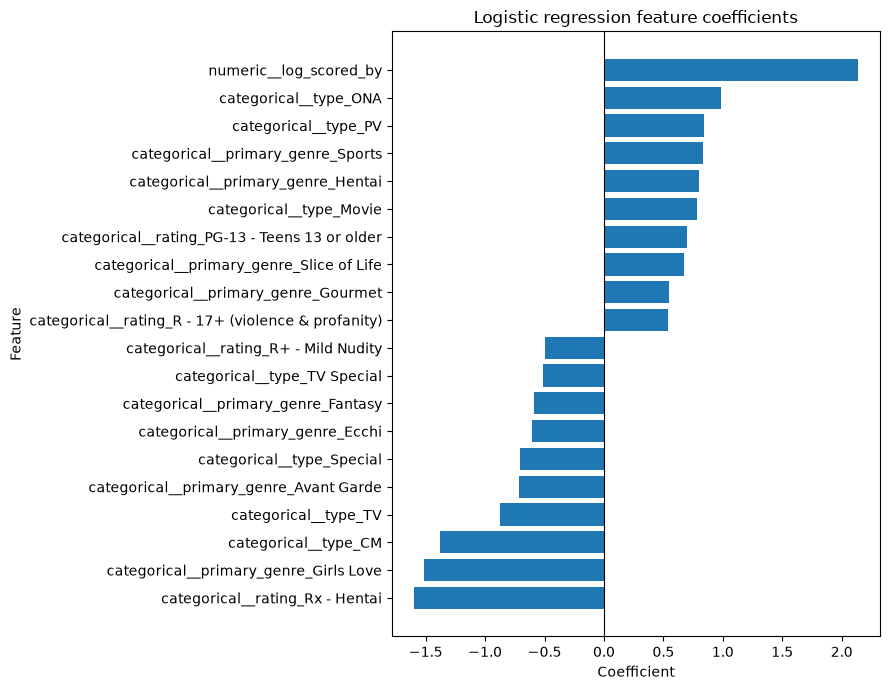

In [28]:
feature_names = best_model.named_steps["preprocessing"].get_feature_names_out()
coefficients = best_model.named_steps["model"].coef_[0]
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
}).sort_values("Coefficient")

print("Features most associated with a lower high-score prediction:")
display(coef_df.head(10))
print("Features most associated with a higher high-score prediction:")
display(coef_df.tail(10).sort_values("Coefficient", ascending=False))

plot_coef = pd.concat([coef_df.head(10), coef_df.tail(10)]).sort_values("Coefficient")
plt.figure(figsize=(9, 7))
plt.barh(plot_coef["Feature"], plot_coef["Coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic regression feature coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 11. What this experiment cannot tell us
- The dataset may not represent every anime.
- The score cut-off of 7.5 is a choice. A different cut-off changes the target groups.
- The model uses only the first genre listed, even though an anime can have several genres.
- Some features have missing values, so the notebook fills them using the median or most common category.
- The number of ratings may reflect how popular or well-known an anime is. It does not explain why viewers give it a particular score.
- Logistic regression is a simple model and may not capture more complicated relationships.

## 12. What did the anime data show?
The model can identify some high-rated anime, but its results need to be considered alongside precision and recall because the high-rated group is smaller. Comparing feature sets shows whether numeric or category information is more useful. The threshold experiment also shows that the definition of a high score affects the results. Overall, the model can find patterns in the dataset, but it cannot reliably explain or predict every anime's score.

## 13. Possible next step
Detailed anime information